# Phase 9 - Neural networks

Code: `src/models/neural_net.py`. A neural network is **linear regression, stacked, with a bend in between**:

```
60 features --[weights + ReLU]--> 64 numbers --[weights + ReLU]--> 32 numbers --[weights]--> points
```

`ReLU(z) = max(z, 0)` is the bend. Without it, stacking layers just gives one big linear regression.
With it, the network can learn curves and "it depends" patterns.

It learns with **gradient descent** (Phase 5) + **backpropagation**: the chain rule, applied from the output backwards,
to find how much each of the ~6,000 weights contributed to the error.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd().parent))
from src.evaluate import load_data, get_split, score
from src.models.neural_net import MLPScratch, TorchModel, NNEnsemble, gradient_check

BLUE, ORANGE, AQUA, YELLOW, INK, INK_2 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "grid.color": "#e8e7e2", "axes.axisbelow": True, "axes.titleweight": "bold",
    "axes.titlesize": 12, "figure.dpi": 110,
})
df = load_data()
train, valid = get_split(df, "valid")

## 1. Is our hand-written backpropagation correct?

Backprop is easy to get subtly wrong. The classic check: for every weight, nudge it up and down by a tiny amount,
measure how the error changes (brute force), and compare with what backprop says. They should agree almost perfectly.

In [2]:
err = gradient_check()
print(f"Largest relative difference between backprop and brute force: {err:.1e}")
print("PASS - backprop is correct" if err < 1e-6 else "FAIL - there's a bug in backprop")

Largest relative difference between backprop and brute force: 1.5e-08
PASS - backprop is correct


## 2. Training the from-scratch network, and early stopping

Each **epoch** = one pass through all training games (in shuffled mini-batches of 512). We watch the error on a held-out
**training** season after every epoch and stop when it stops improving - **early stopping**. Without it, the network keeps
fitting noise (overfitting, same as the deep trees in Phase 7).

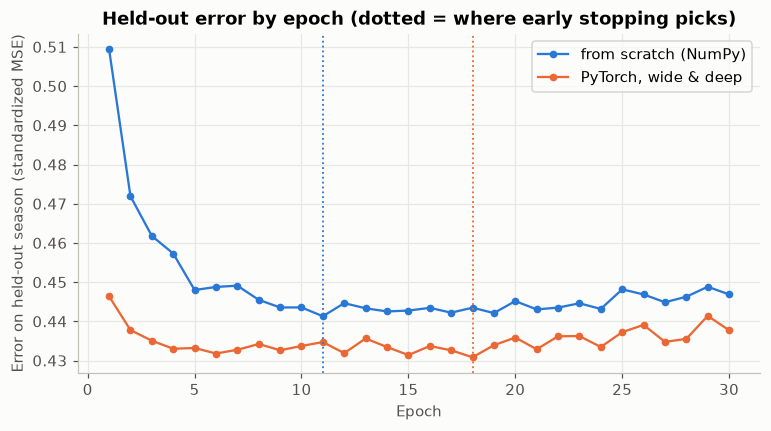

From scratch           best epoch 11, validation MAE 4.619
PyTorch wide & deep    best epoch 18, validation MAE 4.556


In [3]:
scratch = MLPScratch(max_epochs=30, patience=30).fit(train)   # patience=30: let it run all 30 epochs to see the full curve
torch_net = TorchModel(loss="mse", max_epochs=30, patience=30).fit(train)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, len(scratch.inner_history) + 1), scratch.inner_history, "o-", color=BLUE, markersize=4, label="from scratch (NumPy)")
ax.plot(range(1, len(torch_net.inner_history) + 1), torch_net.inner_history, "o-", color=ORANGE, markersize=4, label="PyTorch, wide & deep")
for model, color in [(scratch, BLUE), (torch_net, ORANGE)]:
    ax.axvline(model.best_epoch, color=color, linestyle=":", linewidth=1.2)
ax.set(title="Held-out error by epoch (dotted = where early stopping picks)", xlabel="Epoch",
       ylabel="Error on held-out season (standardized MSE)")
ax.legend()
plt.show()
for name, m in [("From scratch", scratch), ("PyTorch wide & deep", torch_net)]:
    print(f"{name:<22} best epoch {m.best_epoch:>2}, validation MAE {score(valid['PTS'], m.predict(valid))['MAE']:.3f}")

**What this tells us:**
- Both networks learn fast: most of the improvement happens in the **first few epochs**. After that the held-out error flattens,
  gets noisy, and drifts up near the end - the start of overfitting. Early stopping picks the lowest point.
- Notice how **bumpy** the curve is: the "best" epoch is partly luck. That's why this run's PyTorch score (4.56, stopped at epoch 18)
  differs from the main run (4.51, stopped at epoch 6). Neural-network results are noisy - more on that in section 3.
- The plain from-scratch network ends up **worse than linear regression** (4.62 vs 4.52). It has to learn the simple straight-line
  relationship through layers of bends, and starts overfitting before it gets there.
- The PyTorch **wide & deep** version adds a direct linear path (`wide`) next to the deep layers (`deep`) - the Phase 7 lesson again:
  let a linear part handle the straight line, and let the flexible part learn only the leftovers. It starts far better (epoch 1)
  and ends better than the plain network.

## 3. Networks are random - so average several

Every network starts from different random weights and sees the data in a different shuffled order.
So training the *exact same* model twice gives slightly different results. How much?

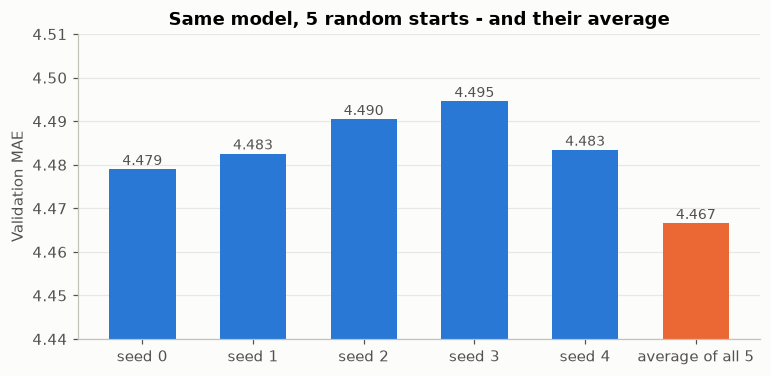

In [4]:
singles, preds = [], []
for seed in range(5):
    p = TorchModel(loss="l1", embeddings=True, seed=seed).fit(train).predict(valid)
    preds.append(p)
    singles.append(score(valid["PTS"], p)["MAE"])
ensemble_mae = score(valid["PTS"], np.mean(preds, axis=0))["MAE"]

fig, ax = plt.subplots(figsize=(8, 3.6))
labels = [f"seed {s}" for s in range(5)] + ["average of all 5"]
values = singles + [ensemble_mae]
ax.bar(labels, values, color=[BLUE] * 5 + [ORANGE], width=0.6)
for i, v in enumerate(values):
    ax.text(i, v + 0.001, f"{v:.3f}", ha="center", color=INK_2, fontsize=9)
ax.set(ylim=(4.44, 4.51), ylabel="Validation MAE", title="Same model, 5 random starts - and their average")
ax.grid(axis="x", visible=False)
plt.show()

**What this tells us:** single runs bounce around by about +/-0.01 - that's as big as most of the "improvements" we've been chasing!
Lesson: **never trust one neural-network run** when comparing models. **Averaging 5 networks** (an *ensemble*) beats every single one of them,
because each network's random quirks cancel out.

## 4. Player embeddings: what did the model learn about individual players?

Each player gets a learned **embedding**: 8 numbers the network can use however it likes, a kind of "fingerprint".
Players it never saw (rookies) share one "unknown player" fingerprint.

To see what the fingerprints *mean*, we compare each prediction **with** the player's own fingerprint vs **with the "unknown" one**.
The difference = what the network learned about *that specific player* beyond his stats.

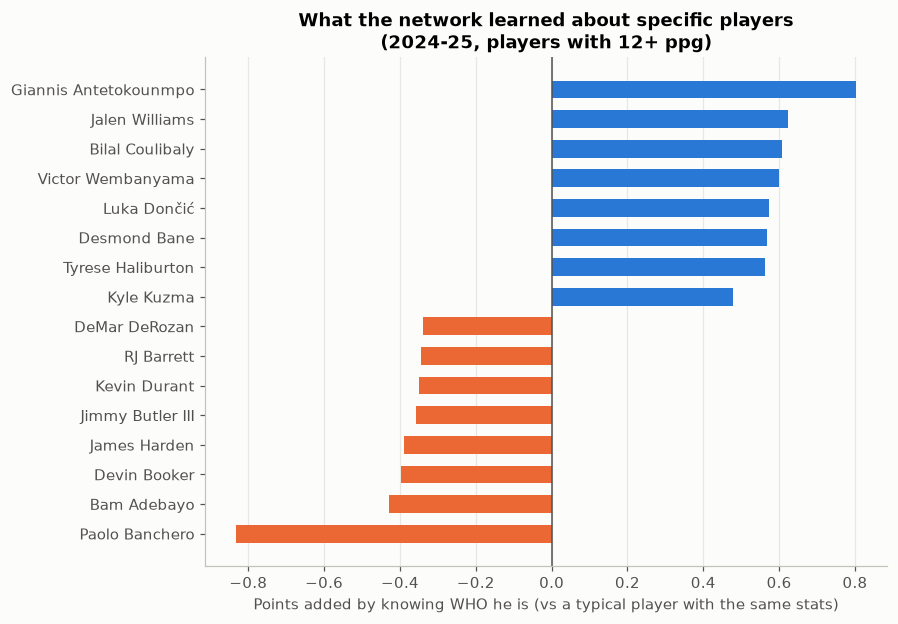

Typical size of the identity effect: 0.28 points


In [5]:
emb_model = TorchModel(loss="l1", embeddings=True).fit(train)
known = valid[valid["PLAYER_ID"].isin(emb_model.player_map)].copy()
with_id = emb_model.predict(known)
saved = emb_model.player_map
emb_model.player_map = {}                         # pretend we don't know anyone
without_id = emb_model.predict(known)
emb_model.player_map = saved
known["identity_effect"] = with_id - without_id

effect = known.groupby("PLAYER_NAME").agg(games=("PTS", "size"), effect=("identity_effect", "mean"), ppg=("PTS", "mean"))
effect = effect[(effect["games"] >= 40) & (effect["ppg"] >= 12)].sort_values("effect")
show = pd.concat([effect.head(8), effect.tail(8)])

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(show.index, show["effect"], color=[ORANGE if v < 0 else BLUE for v in show["effect"]], height=0.6)
ax.axvline(0, color=INK_2, linewidth=1)
ax.set(title="What the network learned about specific players\n(2024-25, players with 12+ ppg)",
       xlabel="Points added by knowing WHO he is (vs a typical player with the same stats)")
ax.grid(axis="y", visible=False)
plt.show()
print(f"Typical size of the identity effect: {known['identity_effect'].abs().mean():.2f} points")

**What this tells us:** for most players, knowing *who* he is changes the prediction by only a fraction of a point - the 60 features already
describe players well. The bars show the players where identity mattered most: positive = he tends to beat what his stats suggest,
negative = he tends to fall short of them. That's why embeddings only helped a little (~0.005 MAE, smaller than the random noise between runs).

## 5. A network that predicts its own uncertainty

In Phase 8 we saw that SGA's ranges were **too wide** and Curry's were about right - one spread formula doesn't fit everyone.
So: let the network output **two numbers per game**: the expected points **and** sigma (how uncertain it is),
trained by maximum likelihood like Phase 6. Did it learn that some players are steadier than others?

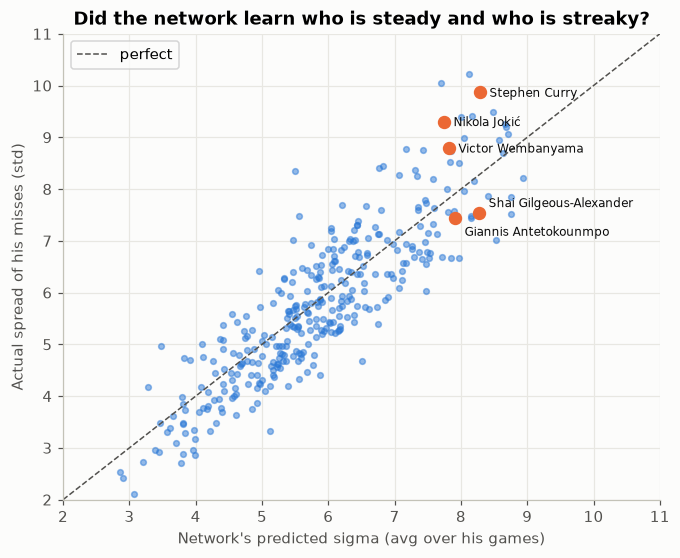

Correlation between predicted and actual spread, per player: 0.88


,games,ppg,predicted_sigma,actual_spread
PLAYER_NAME,,,,
Shai Gilgeous-Alexander,76,32.68,8.28,7.53
Stephen Curry,70,24.54,8.29,9.87


In [6]:
gauss = TorchModel(loss="gauss", embeddings=True).fit(train)
mu, sigma = gauss.mu_sigma(valid)
v = valid.assign(mu=mu, sigma=sigma, err=valid["PTS"] - mu)
per_player = v.groupby("PLAYER_NAME").agg(games=("PTS", "size"), ppg=("PTS", "mean"),
                                          predicted_sigma=("sigma", "mean"), actual_spread=("err", "std"))
per_player = per_player[per_player["games"] >= 40]

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(per_player["predicted_sigma"], per_player["actual_spread"], s=14, color=BLUE, alpha=0.5)
lim = (2, 11)
ax.plot(lim, lim, color=INK_2, linestyle="--", linewidth=1, label="perfect")
for name in ["Shai Gilgeous-Alexander", "Stephen Curry", "Victor Wembanyama", "Nikola Jokić", "Giannis Antetokounmpo"]:
    if name in per_player.index:
        r = per_player.loc[name]
        ax.scatter(r["predicted_sigma"], r["actual_spread"], s=60, color=ORANGE, zorder=3)
        offset = {"Giannis Antetokounmpo": (6, -12), "Shai Gilgeous-Alexander": (6, 4)}.get(name, (6, -3))
        ax.annotate(name, (r["predicted_sigma"], r["actual_spread"]), xytext=offset, textcoords="offset points", fontsize=8, color=INK)
ax.set(xlim=lim, ylim=lim, xlabel="Network's predicted sigma (avg over his games)", ylabel="Actual spread of his misses (std)",
       title="Did the network learn who is steady and who is streaky?")
ax.legend(loc="upper left")
plt.show()
corr = per_player[["predicted_sigma", "actual_spread"]].corr().iloc[0, 1]
print(f"Correlation between predicted and actual spread, per player: {corr:.2f}")
per_player.loc[[n for n in ["Shai Gilgeous-Alexander", "Stephen Curry"] if n in per_player.index]].round(2)

**What this tells us - be careful here:**
- The 0.88 correlation looks impressive, but most of it is the easy part: **bigger scorers get wider ranges**. Any model does that.
- The hard part is players with the **same** scoring level. Look at the orange dots on the right: SGA and Curry both got a predicted sigma
  of about **8.3** - but Curry's real spread was **9.9** and SGA's **7.5**. The network did *not* learn that Curry is streakier than SGA.
- So the Phase 8 problem (SGA's ranges too wide, Curry's too narrow) is **not solved**. A per-player spread probably needs more
  direct evidence - e.g. a feature measuring each player's own historical spread over many games, not just the last 10.

But on the overall distribution scores, this network (log score **-2.994**) only matches the Phase 6 Normal (-2.999) and **loses to the
simulation (-2.955)**. A smart sigma can't fix a wrong *shape*: it's still a symmetric bell curve, with the same zero-points and skew problems as Phase 6.
The simulation's basketball logic (minutes -> shots -> makes) matters more than per-player spread.

## 6. Scoreboard

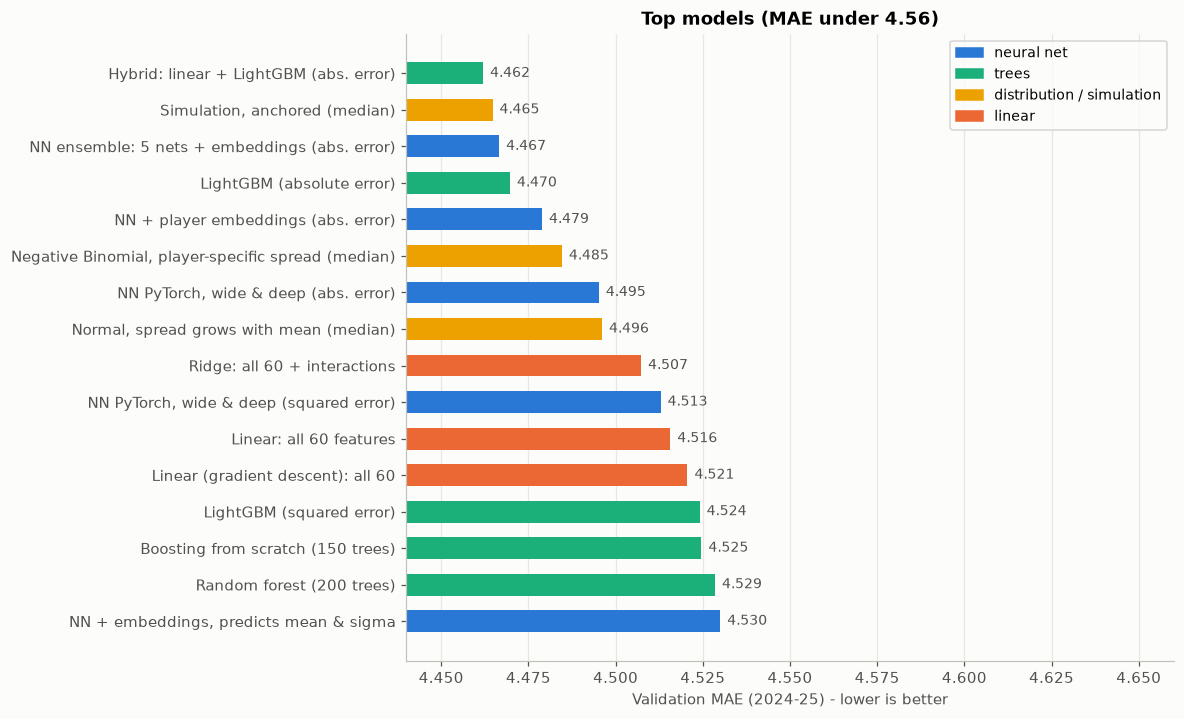

In [7]:
board = pd.read_csv("../results/leaderboard.csv")
board = board[(board["split"] == "valid") & (board["MAE"] < 4.56)].sort_values("MAE", ascending=False)
family = np.select([board["model"].str.contains("NN"), board["model"].str.contains("LightGBM|tree|Tree|forest|Boosting"),
                    board["model"].str.contains("median"), board["model"].str.contains("Linear|Ridge")],
                   ["neural net", "trees", "distribution / simulation", "linear"], "other")
colors = {"neural net": BLUE, "trees": AQUA, "distribution / simulation": YELLOW, "linear": ORANGE, "other": INK_2}
from matplotlib.patches import Patch
fig, ax = plt.subplots(figsize=(9, 0.4 * len(board) + 1))
ax.barh(board["model"], board["MAE"], color=[colors[f] for f in family], height=0.6)
for i, m in enumerate(board["MAE"]):
    ax.text(m + 0.002, i, f"{m:.3f}", va="center", color=INK_2, fontsize=9)
ax.legend(handles=[Patch(color=colors[f], label=f) for f in ["neural net", "trees", "distribution / simulation", "linear"]],
          loc="upper right", fontsize=9)
ax.set(xlim=(4.44, 4.66), xlabel="Validation MAE (2024-25) - lower is better", title="Top models (MAE under 4.56)")
ax.grid(axis="y", visible=False)
plt.show()

## 7. Summary

| Model | MAE | Lesson |
|---|---|---|
| NN from scratch (NumPy) | 4.619 | Backprop verified correct (gradient check 1e-8), but a plain network struggles with the straight-line part |
| PyTorch wide & deep, squared error | 4.513 | A linear "shortcut" fixes that - ties linear regression |
| ... absolute error | ~4.49 | Train on the scoreboard's metric |
| ... + player embeddings | ~4.48 | Player identity adds a little - smaller than run-to-run noise |
| **Ensemble of 5 networks + embeddings** | **4.467** | Averaging random runs is the most reliable gain. Ties the best model (hybrid, 4.462) |
| NN predicting mean & sigma | 4.530 | Spread scales with scoring, but it didn't separate steady (SGA) from streaky (Curry); simulation still wins on distributions |

**The big picture after 9 phases:** neural networks, gradient boosting, and linear regression with good features all land within
~0.05 points of each other. On a table of hand-built features like ours, **the features did most of the work**; model choice matters much less.
That's a common, real-world finding - and a good one to understand.

**Next (Phase 10): the finale.** Combine the best models, run the **one-time final test** on the locked 2025-26 season,
and build `predict.py` to forecast a player's next game.